In [1]:
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import random

data = pd.read_excel('data_for_train.xlsx') 
for i in range(0,4):
    data = data.drop(['Unnamed: '+str(i)], axis=1)
for i in range(12,18):
    data = data.drop(['Unnamed: '+str(i)], axis=1)
    
data = data.drop(['model'],axis=1)
# with open("datafile.txt", "rb") as f:
#     data = f.read().split('\n')
# random.shuffle(data)

# train_data = data[:50]
# test_data = data[50:]

In [2]:
len(data)

3000

In [3]:
data.head()

,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,True,True,False,True,True,True,Allow with condition
1,True,True,True,True,False,False,Allow
2,True,True,True,True,False,False,Allow
3,True,True,False,True,True,True,Allow with condition
4,True,True,True,True,False,False,Allow


In [4]:
data.result = data.result.astype('category')

In [5]:
data.dtypes

result_check_user_location                 bool
result_check_model                         bool
result_check_MAC_address                   bool
result_check_MAC_address_exists            bool
result_check_device_location               bool
result_check_device_location_exists        bool
result                                 category
dtype: object

In [6]:
data = data.apply(LabelEncoder().fit_transform)

In [7]:
data

,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,1,1,0,1,1,1,1
1,1,1,1,1,0,0,0
2,1,1,1,1,0,0,0
3,1,1,0,1,1,1,1
4,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...
2995,1,0,0,0,1,1,2
2996,0,0,0,1,0,1,2
2997,1,1,0,1,0,1,1
2998,1,0,0,0,0,1,2


In [8]:
y = data.drop_duplicates(keep='first')
y = y.reset_index()
y

,index,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,0,1,1,0,1,1,1,1
1,1,1,1,1,1,0,0,0
2,7,1,1,1,1,1,1,0
3,13,1,0,0,0,0,0,2
4,16,0,1,1,1,0,0,2
5,56,1,0,0,0,1,1,2
6,66,1,1,0,0,0,1,2
7,68,1,0,0,1,0,1,2
8,70,1,1,0,0,1,1,2
9,76,1,1,0,1,0,1,1


In [9]:
data = y

In [10]:
import numpy as np
ind = np.random.rand(len(data)) < 0.8

In [11]:
train = data[ind]
test = data[~ind]

In [12]:
print(len(train))

23


In [13]:
label = train.result
train = train.drop(['result'], axis=1)

In [14]:
tlabel = test.result
test = test.drop(['result'], axis=1)

In [15]:
truelabel = pd.DataFrame(tlabel)
truelabel = truelabel.reset_index()

In [16]:
len(tlabel)

4

In [17]:

clf = tree.DecisionTreeClassifier()
clf = clf.fit(train,label )

In [18]:
x = clf.predict(test)

In [19]:
len(x)

4

In [20]:
result_label = pd.DataFrame(columns = ['result'])
result_label.result = x

In [21]:
result_label

,result
0,2
1,2
2,2
3,2


[Text(167.4, 190.26, 'X[0] <= 10.0\ngini = 0.302\nsamples = 23\nvalue = [2, 2, 19]'),
 Text(83.7, 135.9, 'X[0] <= 0.5\ngini = 0.444\nsamples = 3\nvalue = [2, 1, 0]'),
 Text(41.85, 81.53999999999999, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(125.55000000000001, 81.53999999999999, 'gini = 0.0\nsamples = 2\nvalue = [2, 0, 0]'),
 Text(251.10000000000002, 135.9, 'X[0] <= 77.5\ngini = 0.095\nsamples = 20\nvalue = [0, 1, 19]'),
 Text(209.25, 81.53999999999999, 'X[0] <= 73.5\ngini = 0.245\nsamples = 7\nvalue = [0, 1, 6]'),
 Text(167.4, 27.180000000000007, 'gini = 0.0\nsamples = 6\nvalue = [0, 0, 6]'),
 Text(251.10000000000002, 27.180000000000007, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(292.95, 81.53999999999999, 'gini = 0.0\nsamples = 13\nvalue = [0, 0, 13]')]

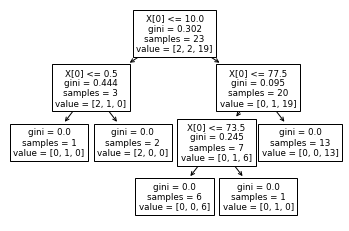

In [22]:
tree.plot_tree(clf.fit(train, label)) 

In [23]:
compare = pd.DataFrame(columns = ['truelabel','predictedlabel'])

compare

In [24]:
compare.truelabel = truelabel.result

In [25]:
compare.predictedlabel = result_label.result

In [26]:
compare

,truelabel,predictedlabel
0,1,2
1,2,2
2,2,2
3,2,2


In [27]:
from sklearn.metrics import accuracy_score
accuracy_score(compare.truelabel, compare.predictedlabel)

0.75